# Reconocimiento de actividades humanas mediante Machine Learning

## Human Activity Recognition Using Smartphones (UCI HAR)

### 1. Introducción

El presente proyecto tiene como objetivo desarrollar modelos de aprendizaje automático para reconocer diferentes actividades humanas a partir de señales obtenidas mediante los sensores de un teléfono inteligente.

Se utilizará el conjunto de datos Human Activity Recognition Using Smartphones, publicado en el repositorio UCI Machine Learning Repository.

Los datos fueron recopilados mediante un teléfono Samsung Galaxy S II ubicado en la cintura de 30 voluntarios, utilizando los sensores acelerómetro y giroscopio para registrar los movimientos durante la realización de seis actividades diferentes.

El conjunto de datos contiene 10.299 observaciones y 561 características numéricas extraídas de las señales originales mediante procedimientos de procesamiento en los dominios del tiempo y la frecuencia.

### 2. Objetivo general

Aplicar técnicas de aprendizaje automático supervisado y no supervisado para analizar, agrupar y clasificar actividades humanas a partir de características obtenidas de sensores inerciales.

### 3. Objetivos específicos

- Realizar un análisis exploratorio para identificar las características y distribución de los datos.
- Aplicar algoritmos de clustering para identificar agrupaciones naturales sin utilizar las etiquetas de actividad.
- Implementar selección de características mediante el método Sequential Floating Forward Selection (SFFS).
- Entrenar una red neuronal artificial para clasificar las actividades.
- Aplicar PCA y LDA para reducir la dimensionalidad y evaluar su efecto sobre la clasificación.
- Comparar los resultados obtenidos mediante las diferentes técnicas.

### 4. Variable objetivo

La variable objetivo corresponde a la actividad realizada por cada participante y contempla seis categorías:

1. WALKING: caminar.
2. WALKING_UPSTAIRS: subir escaleras.
3. WALKING_DOWNSTAIRS: bajar escaleras.
4. SITTING: estar sentado.
5. STANDING: estar de pie.
6. LAYING: estar acostado.

## 2. Instalación e importación de librerías

In [56]:
%pip install -q mlxtend

In [57]:
import os
import zipfile
from google.colab import files

# ==========================================
# 1. SUBIR EL ARCHIVO
# ==========================================

print("Sube el archivo ZIP del dataset HAR")

archivos_subidos = files.upload()

# ==========================================
# 2. DESCOMPRIMIR ARCHIVOS ZIP
# ==========================================

carpeta_destino = "/content/HAR_Dataset"

os.makedirs(carpeta_destino, exist_ok=True)

pendientes = [
    os.path.join("/content", nombre)
    for nombre in archivos_subidos.keys()
    if nombre.lower().endswith(".zip")
]

procesados = set()

while pendientes:

    archivo_actual = pendientes.pop(0)

    if archivo_actual in procesados:
        continue

    procesados.add(archivo_actual)

    if not zipfile.is_zipfile(archivo_actual):
        continue

    print("Descomprimiendo:", os.path.basename(archivo_actual))

    with zipfile.ZipFile(archivo_actual, "r") as zip_ref:
        zip_ref.extractall(carpeta_destino)

    # Buscar ZIP adicionales dentro del contenido extraído
    for ruta, carpetas, archivos in os.walk(carpeta_destino):

        for archivo in archivos:

            if archivo.lower().endswith(".zip"):

                nueva_ruta = os.path.join(ruta, archivo)

                if nueva_ruta not in procesados:
                    pendientes.append(nueva_ruta)

# ==========================================
# 3. LOCALIZAR LA CARPETA DEL DATASET
# ==========================================

RUTA_DATASET = None

for ruta, carpetas, archivos in os.walk(carpeta_destino):

    if (
        "features.txt" in archivos
        and "activity_labels.txt" in archivos
        and "train" in carpetas
        and "test" in carpetas
    ):

        RUTA_DATASET = ruta
        break

# ==========================================
# 4. VERIFICAR RESULTADO
# ==========================================

if RUTA_DATASET is None:

    print("\nNo se encontró la estructura del dataset.")

    print("\nArchivos encontrados:")
    for ruta, carpetas, archivos in os.walk(carpeta_destino):
        for archivo in archivos[:10]:
            print(os.path.join(ruta, archivo))

    raise FileNotFoundError(
        "No se encontró UCI HAR Dataset. "
        "Verifica que hayas subido el ZIP correcto."
    )

print("\n¡DATASET ENCONTRADO CORRECTAMENTE!")
print("Ruta:", RUTA_DATASET)
print("Archivos:", os.listdir(RUTA_DATASET))

Sube el archivo ZIP del dataset HAR


Saving human+activity+recognition+using+smartphones.zip to human+activity+recognition+using+smartphones (4).zip
Descomprimiendo: human+activity+recognition+using+smartphones (4).zip
Descomprimiendo: UCI HAR Dataset.zip

¡DATASET ENCONTRADO CORRECTAMENTE!
Ruta: /content/HAR_Dataset/UCI HAR Dataset
Archivos: ['features_info.txt', 'activity_labels.txt', 'test', 'features.txt', 'train', 'README.txt', '.DS_Store']


## 3. Carga de la base de datos

In [58]:
# ==========================================
# CARGA Y ORGANIZACIÓN DE LOS DATOS
# ==========================================

# Cargar nombres de las características
features = pd.read_csv(
    f"{RUTA_DATASET}/features.txt",
    sep=r"\s+",
    header=None,
    names=["indice", "caracteristica"]
)

# Conservar nombres originales y evitar duplicados
nombres_originales = features["caracteristica"].tolist()

contador = {}
nombres_caracteristicas = []

for nombre in nombres_originales:
    if nombre in contador:
        contador[nombre] += 1
        nombre_unico = f"{nombre}_{contador[nombre]}"
    else:
        contador[nombre] = 0
        nombre_unico = nombre

    nombres_caracteristicas.append(nombre_unico)

# Cargar entrenamiento
X_train = pd.read_csv(
    f"{RUTA_DATASET}/train/X_train.txt",
    sep=r"\s+",
    header=None
)

X_train.columns = nombres_caracteristicas

y_train = pd.read_csv(
    f"{RUTA_DATASET}/train/y_train.txt",
    header=None,
    names=["Actividad"]
)

subject_train = pd.read_csv(
    f"{RUTA_DATASET}/train/subject_train.txt",
    header=None,
    names=["Sujeto"]
)

# Cargar prueba
X_test = pd.read_csv(
    f"{RUTA_DATASET}/test/X_test.txt",
    sep=r"\s+",
    header=None
)

X_test.columns = nombres_caracteristicas

y_test = pd.read_csv(
    f"{RUTA_DATASET}/test/y_test.txt",
    header=None,
    names=["Actividad"]
)

subject_test = pd.read_csv(
    f"{RUTA_DATASET}/test/subject_test.txt",
    header=None,
    names=["Sujeto"]
)

# Cargar nombres de las actividades
activity_labels = pd.read_csv(
    f"{RUTA_DATASET}/activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["ID", "Nombre_Actividad"]
)

# Convertir códigos a nombres
mapa_actividades = dict(
    zip(activity_labels["ID"], activity_labels["Nombre_Actividad"])
)

y_train["Actividad"] = y_train["Actividad"].map(mapa_actividades)
y_test["Actividad"] = y_test["Actividad"].map(mapa_actividades)

# Unificar conjuntos
X = pd.concat([X_train, X_test], ignore_index=True)

y = pd.concat(
    [y_train, y_test],
    ignore_index=True
)["Actividad"]

sujetos = pd.concat(
    [subject_train, subject_test],
    ignore_index=True
)["Sujeto"]

# Crear DataFrame general
df = X.copy()
df["Actividad"] = y
df["Sujeto"] = sujetos

# Verificación
print("BASE DE DATOS CARGADA CORRECTAMENTE")
print("-----------------------------------")
print("Total de muestras:", df.shape[0])
print("Características:", X.shape[1])
print("Actividades:", y.nunique())
print("Sujetos:", sujetos.nunique())
print("Columnas duplicadas:", X.columns.duplicated().sum())

BASE DE DATOS CARGADA CORRECTAMENTE
-----------------------------------
Total de muestras: 10299
Características: 561
Actividades: 6
Sujetos: 30
Columnas duplicadas: 0


## Descripción de las variables

El conjunto de datos contiene 561 características predictoras, obtenidas mediante el procesamiento de señales registradas por los sensores de un teléfono inteligente Samsung Galaxy S II.

Se utilizaron dos sensores principales:

- **Acelerómetro:** mide la aceleración en los ejes X, Y y Z.
- **Giroscopio:** mide la velocidad angular en los ejes X, Y y Z.

A partir de estas señales se calcularon características estadísticas y frecuenciales, como media, desviación estándar, energía, entropía y magnitudes de frecuencia.

### Variable objetivo: Actividad

Representa el movimiento realizado por el participante y contiene seis categorías:

1. WALKING: caminar.
2. WALKING_UPSTAIRS: subir escaleras.
3. WALKING_DOWNSTAIRS: bajar escaleras.
4. SITTING: estar sentado.
5. STANDING: estar de pie.
6. LAYING: estar acostado.

### Variable identificadora: Sujeto

Identifica a cada uno de los 30 participantes. No se utilizará como característica predictora.

### Tipo de problema

Se trata de un problema de clasificación multiclase, cuyo objetivo es identificar la actividad humana a partir de las características extraídas de las señales de los sensores.

## 4. Análisis exploratorio de datos (EDA)

In [59]:
# Dimensiones del conjunto de datos
print("Dimensiones del dataset:", df.shape)

print("\nNúmero de muestras:", X.shape[0])
print("Número de características:", X.shape[1])
print("Número de actividades:", y.nunique())
print("Número de sujetos:", sujetos.nunique())

# Información general
print("\nInformación de las variables:")
df.info()

Dimensiones del dataset: (10299, 563)

Número de muestras: 10299
Número de características: 561
Número de actividades: 6
Número de sujetos: 30

Información de las variables:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10299 entries, 0 to 10298
Columns: 563 entries, tBodyAcc-mean()-X to Sujeto
dtypes: float64(561), int64(1), object(1)
memory usage: 44.2+ MB


In [60]:
# Estadísticas descriptivas
estadisticas = X.describe().T

display(estadisticas)

,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,10299.0,0.274347,0.067628,-1.0,0.262625,0.277174,0.288354,1.0
tBodyAcc-mean()-Y,10299.0,-0.017743,0.037128,-1.0,-0.024902,-0.017162,-0.010625,1.0
tBodyAcc-mean()-Z,10299.0,-0.108925,0.053033,-1.0,-0.121019,-0.108596,-0.097589,1.0
tBodyAcc-std()-X,10299.0,-0.607784,0.438694,-1.0,-0.992360,-0.943030,-0.250293,1.0
tBodyAcc-std()-Y,10299.0,-0.510191,0.500240,-1.0,-0.976990,-0.835032,-0.057336,1.0
...,...,...,...,...,...,...,...,...
"angle(tBodyGyroMean,gravityMean)",10299.0,0.017683,0.616188,-1.0,-0.493108,0.017192,0.536137,1.0
"angle(tBodyGyroJerkMean,gravityMean)",10299.0,-0.009219,0.484770,-1.0,-0.389041,-0.007186,0.365996,1.0
"angle(X,gravityMean)",10299.0,-0.496522,0.511158,-1.0,-0.817288,-0.715631,-0.521503,1.0
"angle(Y,gravityMean)",10299.0,0.063255,0.305468,-1.0,0.002151,0.182028,0.250790,1.0


In [61]:
# Valores faltantes
faltantes = df.isnull().sum().sum()

# Valores infinitos
infinitos = np.isinf(X.to_numpy()).sum()

# Registros duplicados
duplicados = df.duplicated().sum()

print("CALIDAD DE LOS DATOS")
print("--------------------")
print("Valores faltantes:", faltantes)
print("Registros duplicados:", duplicados)

CALIDAD DE LOS DATOS
--------------------
Valores faltantes: 0
Registros duplicados: 0


Actividad
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


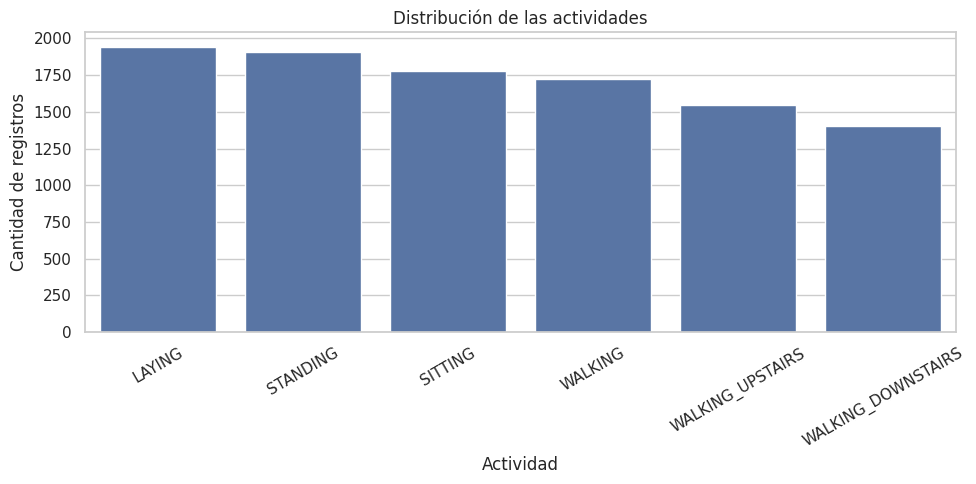

In [62]:
# Contar registros por actividad
distribucion = y.value_counts()

print(distribucion)

# Gráfica de distribución
plt.figure(figsize=(10, 5))

sns.countplot(
    x=y,
    order=distribucion.index
)

plt.title("Distribución de las actividades")
plt.xlabel("Actividad")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

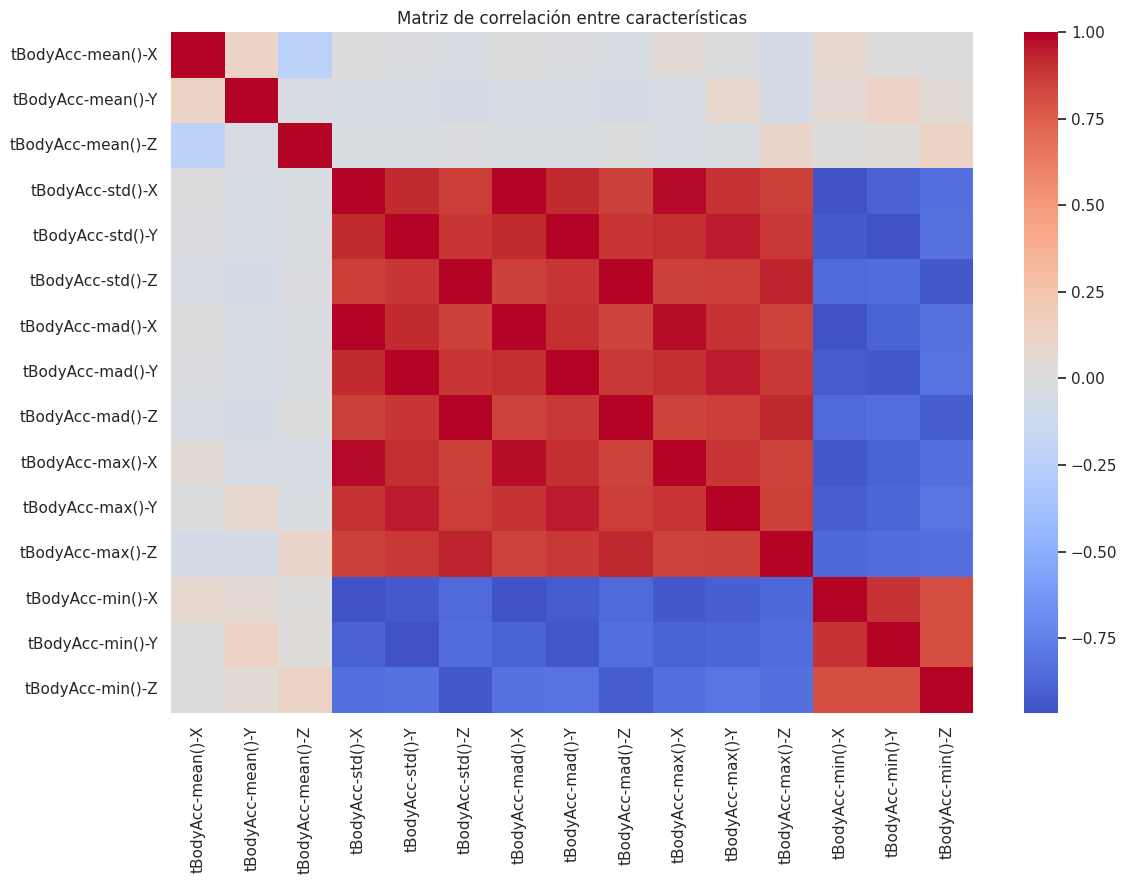

In [63]:
# Seleccionar 15 características
caracteristicas_corr = X.columns[:15]

# Calcular correlaciones
matriz_corr = X[caracteristicas_corr].corr()

# Visualizar matriz
plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_corr,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Matriz de correlación entre características")
plt.tight_layout()
plt.show()

### Conclusión del EDA

El análisis exploratorio permite identificar que el conjunto de datos presenta características con diferentes distribuciones, niveles de dispersión y relaciones entre sí. Además, algunas variables muestran capacidad para diferenciar las actividades humanas. Por tanto, la base de datos resulta adecuada para continuar con los algoritmos de clustering, selección de características y clasificación mediante redes neuronales artificiales.

# 2. Aprendizaje no supervisado: Clustering

En esta etapa se aplicarán tres algoritmos de agrupamiento: K-means, clustering jerárquico aglomerativo y DBSCAN.

El propósito es identificar agrupaciones naturales en las características extraídas de los sensores, sin utilizar las etiquetas de actividad durante el entrenamiento.

Posteriormente, los resultados se compararán con las seis actividades reales mediante métricas como Adjusted Rand Index (ARI), Normalized Mutual Information (NMI) y Silhouette Score.

Debido al costo computacional de los algoritmos de agrupamiento sobre las 10.299 observaciones y las 561 características, se utilizará una muestra representativa de 3.000 registros para esta etapa.

In [64]:
# Seleccionar una muestra aleatoria de 3000 registros
indices_muestra = X.sample(
    n=3000,
    random_state=RANDOM_STATE
).index

# Datos que utilizarán los algoritmos
X_cluster = X.loc[indices_muestra].copy()

# Etiquetas reales reservadas para evaluación
y_cluster_real = y.loc[indices_muestra].copy()

# Estandarizar las características
scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print("Preparación para clustering completada")
print("---------------------------------------")
print("Número de muestras:", X_cluster_scaled.shape[0])
print("Número de características:", X_cluster_scaled.shape[1])
print("Media aproximada:", np.mean(X_cluster_scaled).round(4))
print("Desviación estándar:", np.std(X_cluster_scaled).round(4))

Preparación para clustering completada
---------------------------------------
Número de muestras: 3000
Número de características: 561
Media aproximada: 0.0
Desviación estándar: 1.0


In [65]:
# Diferentes cantidades de clusters
valores_k = [2, 3, 4, 5, 6, 7, 8]

resultados_kmeans = []

modelos_kmeans = {}

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_cluster_scaled)

    modelos_kmeans[k] = modelo

    # Evaluación de los agrupamientos
    ari = adjusted_rand_score(y_cluster_real, etiquetas)
    nmi = normalized_mutual_info_score(y_cluster_real, etiquetas)
    silueta = silhouette_score(
        X_cluster_scaled,
        etiquetas,
        sample_size=1000,
        random_state=RANDOM_STATE
    )

    resultados_kmeans.append({
        "Clusters": k,
        "Inercia": modelo.inertia_,
        "ARI": ari,
        "NMI": nmi,
        "Silhouette": silueta
    })

tabla_kmeans = pd.DataFrame(resultados_kmeans)

display(tabla_kmeans)

,Clusters,Inercia,ARI,NMI,Silhouette
0,2,949357.538879,0.329323,0.543421,0.394848
1,3,847826.225340,0.326382,0.510344,0.310738
2,4,806466.355362,0.299131,0.471934,0.154982
3,5,770862.893497,0.294032,0.463354,0.141972
4,6,748123.927372,0.415274,0.560075,0.113034
5,7,731630.047685,0.444685,0.566000,0.071585
6,8,714946.347600,0.396762,0.537006,0.082383


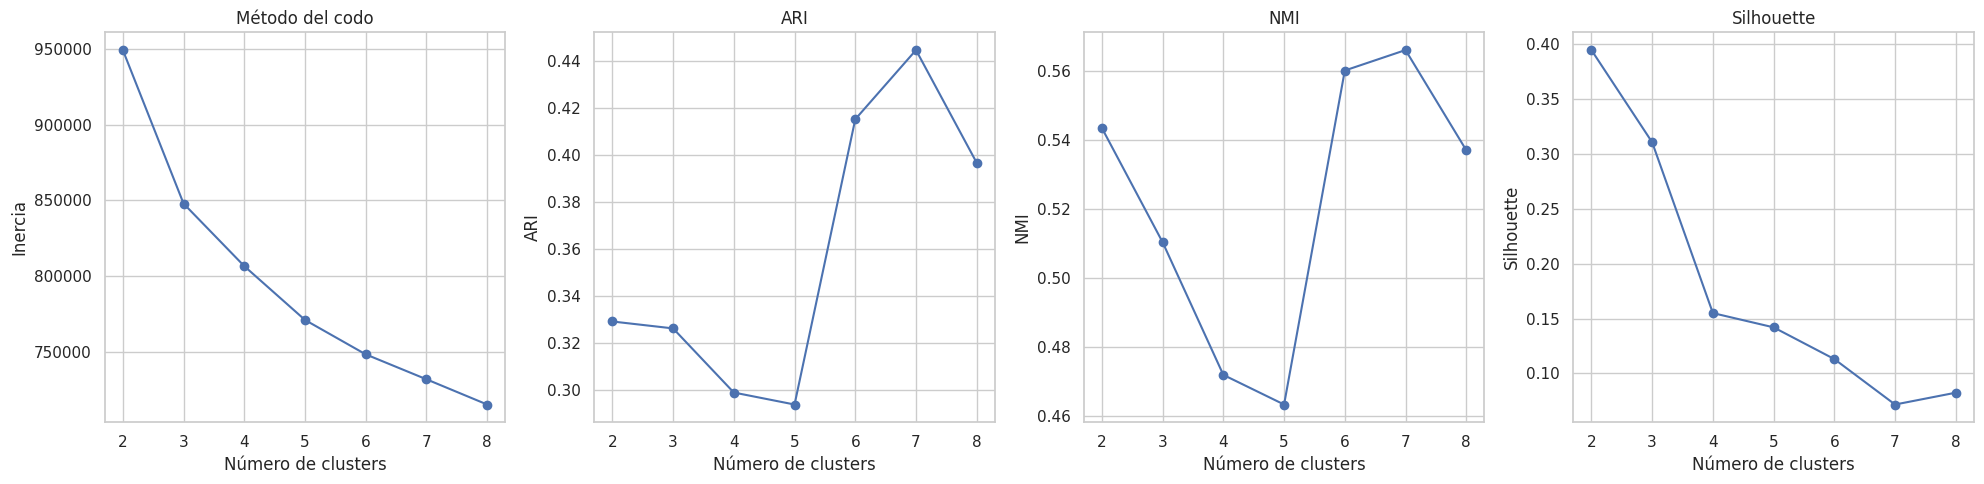

In [66]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Método del codo
axes[0].plot(
    tabla_kmeans["Clusters"],
    tabla_kmeans["Inercia"],
    marker="o"
)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters")
axes[0].set_ylabel("Inercia")
axes[0].set_xticks(valores_k)
axes[0].grid(True)

# Métricas de evaluación
metricas = ["ARI", "NMI", "Silhouette"]

for i, metrica in enumerate(metricas, start=1):
    axes[i].plot(
        tabla_kmeans["Clusters"],
        tabla_kmeans[metrica],
        marker="o"
    )
    axes[i].set_title(metrica)
    axes[i].set_xlabel("Número de clusters")
    axes[i].set_ylabel(metrica)
    axes[i].set_xticks(valores_k)
    axes[i].grid(True)

plt.tight_layout()
plt.show()

### Análisis de resultados de K-means

Se comparó el desempeño de K-means utilizando diferentes cantidades de clusters, desde 2 hasta 8.

Para evaluar los resultados se utilizaron tres métricas:

- **ARI:** permite medir la similitud entre los agrupamientos encontrados y las actividades reales.
- **NMI:** mide la información compartida entre los clusters y las etiquetas originales.
- **Silhouette:** evalúa la cohesión interna y separación entre los grupos.

Estas métricas permiten analizar tanto la correspondencia de los agrupamientos con las actividades reales como la calidad de su estructura interna. Se prestará especial atención al modelo de seis clusters, debido a que el conjunto de datos contiene seis actividades humanas.

## 3. Clustering jerárquico aglomerativo

El clustering jerárquico aglomerativo es un algoritmo no supervisado que comienza considerando cada observación como un grupo individual y posteriormente fusiona los grupos más cercanos hasta alcanzar una cantidad determinada de clusters.

En este proyecto se utilizará el método de enlace Ward, que busca minimizar el incremento de la variabilidad interna al unir dos grupos.

Se evaluarán diferentes cantidades de clusters (2 a 8), utilizando las métricas ARI, NMI y Silhouette para comparar los resultados.

In [67]:
# Seleccionar una muestra representativa de 3000 observaciones
np.random.seed(RANDOM_STATE)

indices_muestra = np.random.choice(
    len(X_cluster_scaled),
    size=3000,
    replace=False
)

# Seleccionar las observaciones por posición
X_jerarquico = X_cluster_scaled[indices_muestra]

if isinstance(y_cluster_real, (pd.DataFrame, pd.Series)):
    y_jerarquico_real = y_cluster_real.iloc[indices_muestra].to_numpy().ravel()
else:
    y_jerarquico_real = np.asarray(y_cluster_real)[indices_muestra].ravel()

# Evaluar diferentes números de clusters
valores_k_jerarquico = [2, 3, 4, 5, 6, 7, 8]

resultados_jerarquico = []
modelos_jerarquicos = {}

for k in valores_k_jerarquico:

    print(f"Entrenando clustering jerárquico con k={k}...")

    modelo = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    etiquetas = modelo.fit_predict(X_jerarquico)

    modelos_jerarquicos[k] = modelo

    ari = adjusted_rand_score(
        y_jerarquico_real,
        etiquetas
    )

    nmi = normalized_mutual_info_score(
        y_jerarquico_real,
        etiquetas
    )

    silueta = silhouette_score(
        X_jerarquico,
        etiquetas,
        sample_size=1000,
        random_state=RANDOM_STATE
    )

    resultados_jerarquico.append({
        "Clusters": k,
        "ARI": ari,
        "NMI": nmi,
        "Silhouette": silueta
    })

tabla_jerarquico = pd.DataFrame(resultados_jerarquico)

print("\nResultados del clustering jerárquico:")
display(tabla_jerarquico)

Entrenando clustering jerárquico con k=2...
Entrenando clustering jerárquico con k=3...
Entrenando clustering jerárquico con k=4...
Entrenando clustering jerárquico con k=5...
Entrenando clustering jerárquico con k=6...
Entrenando clustering jerárquico con k=7...
Entrenando clustering jerárquico con k=8...

Resultados del clustering jerárquico:


,Clusters,ARI,NMI,Silhouette
0,2,0.332300,0.554813,0.394483
1,3,0.335804,0.532183,0.303049
2,4,0.330781,0.496701,0.134330
3,5,0.324567,0.490455,0.129792
4,6,0.430810,0.578246,0.100104
5,7,0.433134,0.577509,0.102911
6,8,0.432225,0.569649,0.102685


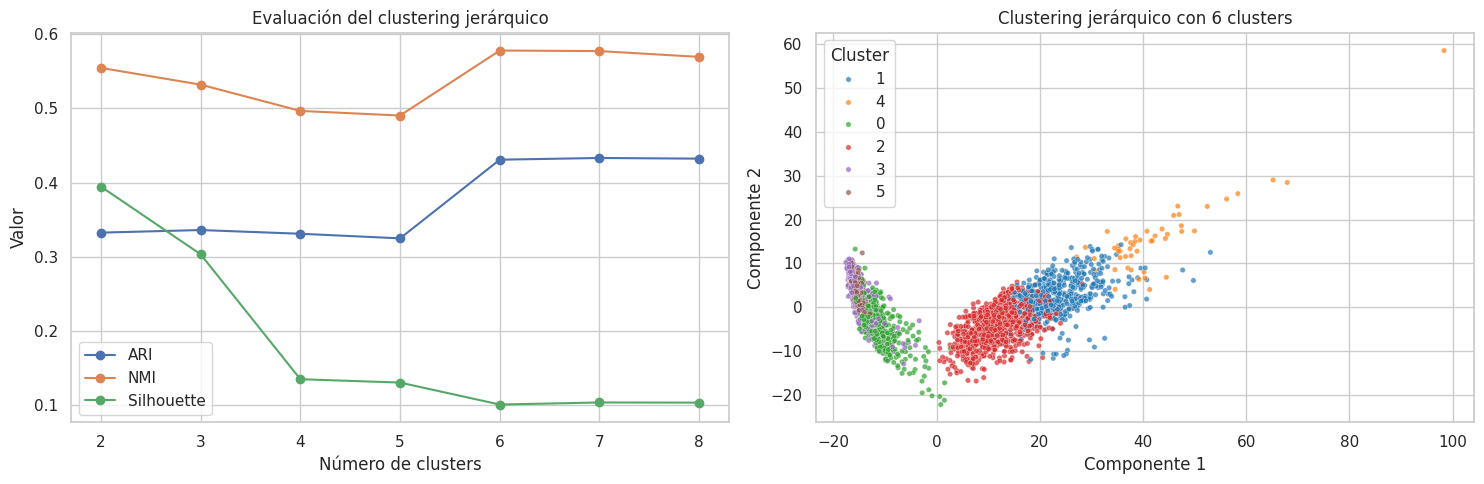

In [68]:
# Obtener las etiquetas del modelo jerárquico con 6 clusters
etiquetas_jerarquico = modelos_jerarquicos[6].labels_

# Crear visualización PCA
pca_visual = PCA(n_components=2, random_state=RANDOM_STATE)
X_visual = pca_visual.fit_transform(X_jerarquico)

df_visual = pd.DataFrame({
    "Componente 1": X_visual[:, 0],
    "Componente 2": X_visual[:, 1],
    "Cluster": etiquetas_jerarquico.astype(str)
})

# Mostrar métricas y visualización
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for metrica in ["ARI", "NMI", "Silhouette"]:
    axes[0].plot(
        tabla_jerarquico["Clusters"],
        tabla_jerarquico[metrica],
        marker="o",
        label=metrica
    )

axes[0].set_title("Evaluación del clustering jerárquico")
axes[0].set_xlabel("Número de clusters")
axes[0].set_ylabel("Valor")
axes[0].legend()
axes[0].grid(True)

sns.scatterplot(
    data=df_visual,
    x="Componente 1",
    y="Componente 2",
    hue="Cluster",
    palette="tab10",
    s=15,
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title("Clustering jerárquico con 6 clusters")
axes[1].legend(title="Cluster")

plt.tight_layout()
plt.show()

## 3. Clustering mediante DBSCAN

DBSCAN es un algoritmo de clustering no supervisado basado en la densidad de los datos. Permite identificar grupos sin definir previamente su cantidad y detectar observaciones consideradas ruido.

Utiliza dos parámetros principales:

- **eps:** distancia máxima para considerar dos observaciones vecinas.
- **min_samples:** número mínimo de observaciones necesarias para formar una región densa.

Se aplicará sobre los datos estandarizados y se evaluará mediante ARI, NMI y Silhouette, utilizando las etiquetas reales únicamente para comparar los resultados.

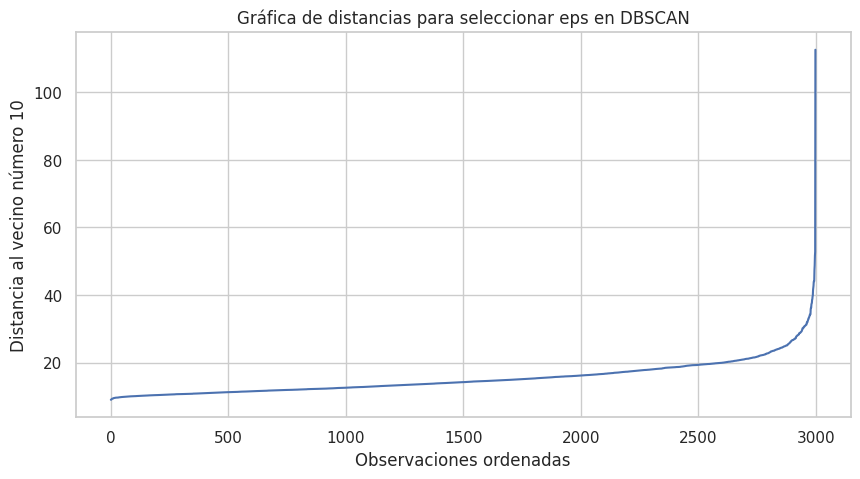

In [69]:
from sklearn.neighbors import NearestNeighbors

# Número mínimo de vecinos
min_samples_dbscan = 10

# Calcular distancias a los vecinos más cercanos
vecinos = NearestNeighbors(
    n_neighbors=min_samples_dbscan
)

vecinos.fit(X_jerarquico)

distancias, indices = vecinos.kneighbors(X_jerarquico)

# Ordenar las distancias del vecino más lejano
distancias_ordenadas = np.sort(distancias[:, -1])

# Graficar las distancias
plt.figure(figsize=(10, 5))

plt.plot(distancias_ordenadas)

plt.title("Gráfica de distancias para seleccionar eps en DBSCAN")
plt.xlabel("Observaciones ordenadas")
plt.ylabel("Distancia al vecino número 10")
plt.grid(True)

plt.show()

In [70]:
# Ajuste fino de los parámetros de DBSCAN
valores_eps = [14, 15, 16, 17]
valores_min_samples = [5, 10, 15]

resultados_dbscan_final = []
modelos_dbscan_final = {}

for min_samples in valores_min_samples:
    for eps in valores_eps:

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        etiquetas = modelo.fit_predict(X_jerarquico)

        modelos_dbscan_final[(eps, min_samples)] = modelo

        clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
        ruido = np.sum(etiquetas == -1)

        ari = adjusted_rand_score(y_jerarquico_real, etiquetas)
        nmi = normalized_mutual_info_score(y_jerarquico_real, etiquetas)

        mascara = etiquetas != -1
        etiquetas_validas = etiquetas[mascara]

        if 2 <= len(np.unique(etiquetas_validas)) < len(etiquetas_validas):
            silueta = silhouette_score(
                X_jerarquico[mascara],
                etiquetas_validas,
                sample_size=min(1000, len(etiquetas_validas)),
                random_state=RANDOM_STATE
            )
        else:
            silueta = np.nan

        resultados_dbscan_final.append({
            "Eps": eps,
            "Min_samples": min_samples,
            "Clusters": clusters,
            "Ruido": ruido,
            "ARI": ari,
            "NMI": nmi,
            "Silhouette": silueta
        })

tabla_dbscan_final = pd.DataFrame(resultados_dbscan_final)

display(
    tabla_dbscan_final.sort_values(
        by="ARI",
        ascending=False
    ).reset_index(drop=True)
)

,Eps,Min_samples,Clusters,Ruido,ARI,NMI,Silhouette
0,16,5,8,683,0.304461,0.452957,0.294360
1,16,10,3,773,0.300537,0.449608,0.336909
2,16,15,2,827,0.295783,0.444229,0.412656
3,15,5,6,864,0.290506,0.437167,0.323482
4,15,10,3,933,0.284683,0.431693,0.359972
5,15,15,2,1016,0.275431,0.422267,0.409481
6,14,5,6,1076,0.259613,0.404894,0.338763
7,14,10,2,1200,0.250027,0.395322,0.420693
8,14,15,4,1289,0.238464,0.385274,0.357264
9,17,15,1,637,0.068306,0.136613,NaN


### Visualización de los resultados de DBSCAN

Se seleccionó la configuración con `eps = 16` y `min_samples = 5`, debido a que obtuvo los mejores valores de ARI y NMI. A continuación, se visualizarán los clusters identificados mediante PCA y se analizará la distribución de las observaciones, incluyendo aquellas clasificadas como ruido.

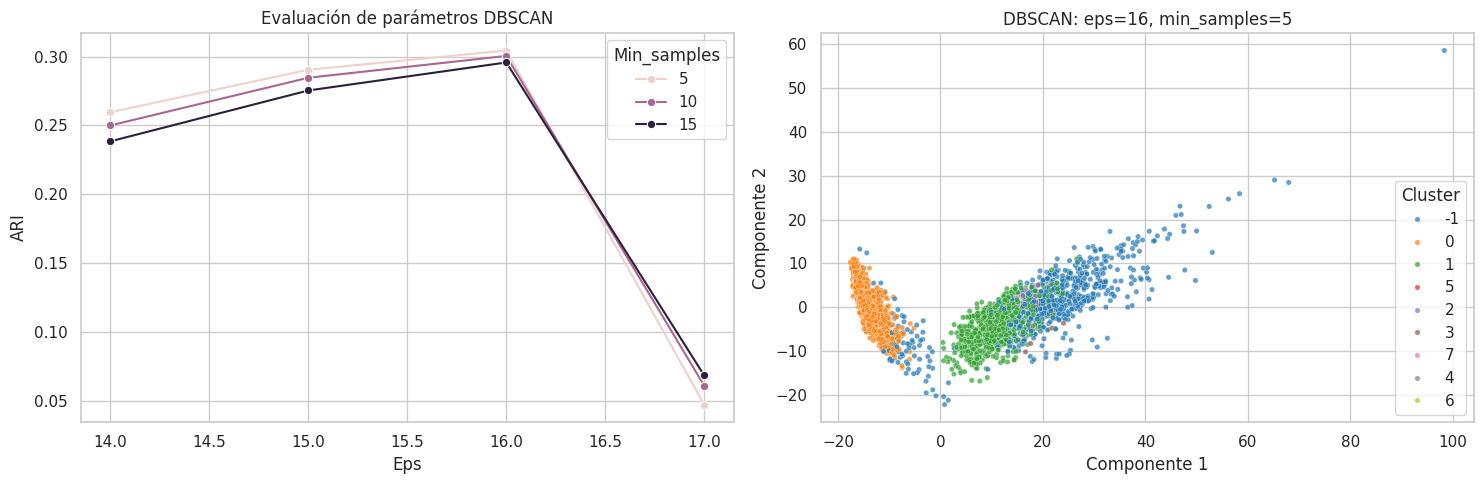

In [74]:
# Seleccionar el modelo DBSCAN
modelo_dbscan_seleccionado = modelos_dbscan_final[(16, 5)]
etiquetas_dbscan = modelo_dbscan_seleccionado.labels_

# Crear visualización
df_visual_dbscan = pd.DataFrame({
    "Componente 1": X_visual[:, 0],
    "Componente 2": X_visual[:, 1],
    "Cluster": etiquetas_dbscan.astype(str)
})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Comparación de parámetros
sns.lineplot(
    data=tabla_dbscan_final,
    x="Eps",
    y="ARI",
    hue="Min_samples",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Evaluación de parámetros DBSCAN")
axes[0].grid(True)

# Visualización de clusters
sns.scatterplot(
    data=df_visual_dbscan,
    x="Componente 1",
    y="Componente 2",
    hue="Cluster",
    palette="tab10",
    s=15,
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title("DBSCAN: eps=16, min_samples=5")

plt.tight_layout()
plt.show()

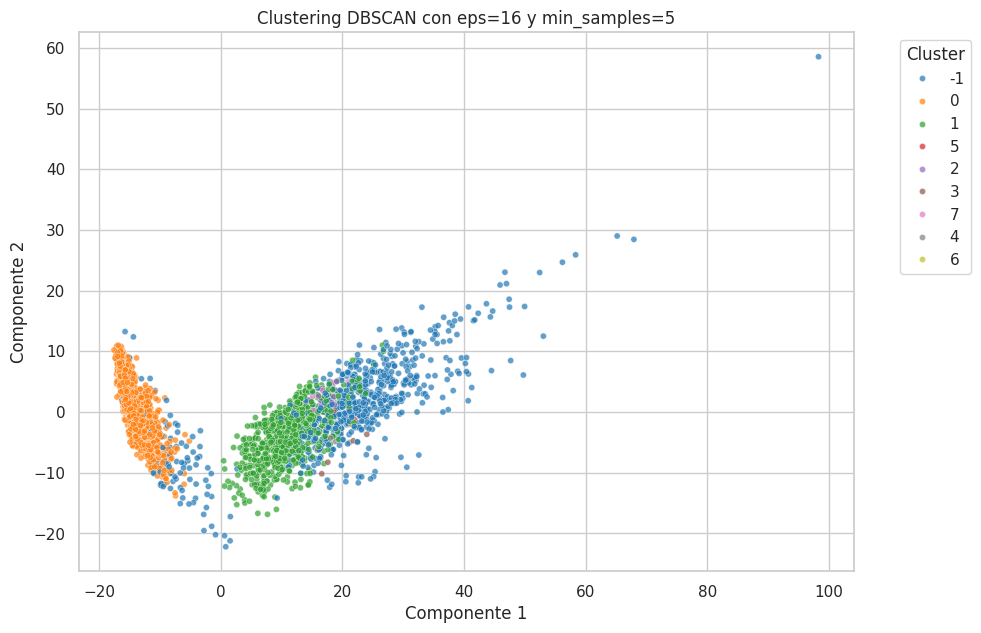

In [71]:
# Obtener el modelo seleccionado
modelo_dbscan_seleccionado = modelos_dbscan_final[(16, 5)]

etiquetas_dbscan = modelo_dbscan_seleccionado.labels_

# Crear conjunto de datos para visualizar
df_visual_dbscan = pd.DataFrame({
    "Componente 1": X_visual[:, 0],
    "Componente 2": X_visual[:, 1],
    "Cluster": etiquetas_dbscan.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_visual_dbscan,
    x="Componente 1",
    y="Componente 2",
    hue="Cluster",
    palette="tab10",
    s=20,
    alpha=0.7
)

plt.title("Clustering DBSCAN con eps=16 y min_samples=5")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1))
plt.show()

### Análisis de resultados de DBSCAN

DBSCAN permitió identificar 8 clusters utilizando `eps = 16` y `min_samples = 5`. El modelo obtuvo un ARI de 0.3045 y un NMI de 0.4530, clasificando 683 observaciones como ruido.

La visualización mediante PCA muestra agrupaciones de diferentes tamaños, algunas con separación y otras con solapamiento. Esto evidencia que existen regiones de distinta densidad en los datos, aunque no todas las actividades pueden diferenciarse claramente.

En general, DBSCAN permitió detectar agrupaciones y observaciones atípicas sin establecer previamente el número de clusters.

,Algoritmo,ARI,NMI,Silhouette
0,K-means,0.4147,0.5602,0.1126
1,Jerárquico,0.4308,0.5782,0.1001
2,DBSCAN,0.3045,0.4530,0.2944


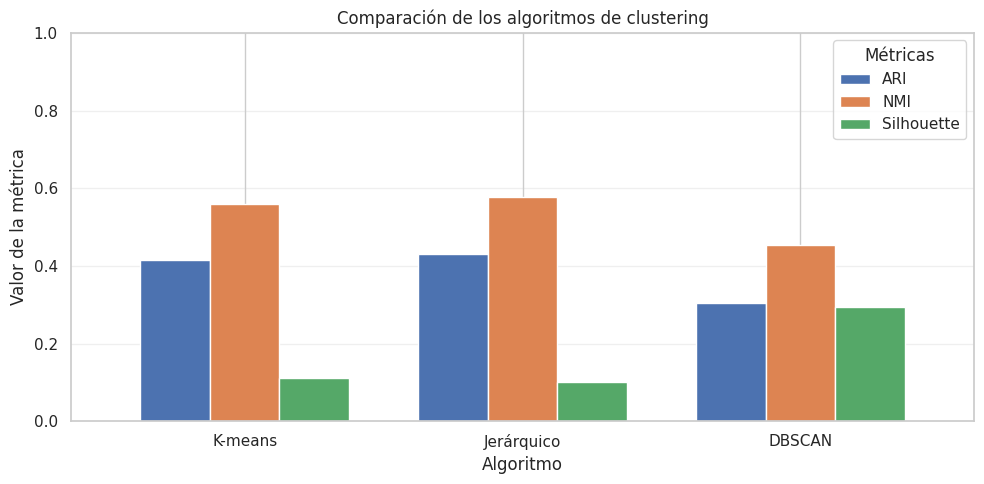

In [75]:
# Comparación de los tres algoritmos de clustering

modelos_comparacion = {
    "K-means": etiquetas_kmeans,
    "Jerárquico": etiquetas_jerarquico,
    "DBSCAN": etiquetas_dbscan
}

resultados_comparacion = []

for nombre, etiquetas in modelos_comparacion.items():

    ari = adjusted_rand_score(y_jerarquico_real, etiquetas)
    nmi = normalized_mutual_info_score(y_jerarquico_real, etiquetas)

    # Excluir el ruido de DBSCAN para calcular Silhouette
    if nombre == "DBSCAN":
        mascara = etiquetas != -1
        X_sil = X_jerarquico[mascara]
        etiquetas_sil = etiquetas[mascara]
    else:
        X_sil = X_jerarquico
        etiquetas_sil = etiquetas

    if 2 <= len(np.unique(etiquetas_sil)) < len(etiquetas_sil):
        silueta = silhouette_score(
            X_sil,
            etiquetas_sil,
            sample_size=min(1000, len(etiquetas_sil)),
            random_state=RANDOM_STATE
        )
    else:
        silueta = np.nan

    resultados_comparacion.append({
        "Algoritmo": nombre,
        "ARI": ari,
        "NMI": nmi,
        "Silhouette": silueta
    })

tabla_comparacion = pd.DataFrame(resultados_comparacion)

display(tabla_comparacion.round(4))

# Gráfica comparativa
tabla_grafica = tabla_comparacion.set_index("Algoritmo")

tabla_grafica.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

plt.title("Comparación de los algoritmos de clustering")
plt.xlabel("Algoritmo")
plt.ylabel("Valor de la métrica")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Métricas")
plt.tight_layout()
plt.show()

## Conclusiones del clustering

Se evaluaron tres algoritmos de aprendizaje no supervisado: K-means, clustering jerárquico y DBSCAN, utilizando los índices ARI, NMI y Silhouette.

El clustering jerárquico obtuvo los mejores resultados de ARI (0.4308) y NMI (0.5782), mostrando la mayor correspondencia con las actividades reales. K-means presentó resultados cercanos, mientras que DBSCAN obtuvo un Silhouette de 0.2944, aunque clasificó 683 observaciones como ruido.

Los resultados evidencian que las técnicas de clustering lograron identificar estructuras en los datos, pero no consiguieron separar completamente las seis actividades. Esto puede relacionarse con las similitudes entre algunos patrones de movimiento.

En conclusión, el clustering jerárquico presentó el mejor desempeño respecto a la correspondencia con las etiquetas reales, mientras que DBSCAN permitió identificar agrupaciones basadas en densidad y observaciones consideradas ruido.

# 3. Aprendizaje supervisado: reducción de dimensionalidad y clasificación con RNA

En esta segunda etapa se desarrollarán modelos de clasificación mediante una red neuronal artificial (RNA), con el propósito de reconocer las seis actividades humanas a partir de las características obtenidas de los sensores.

Se evaluarán tres estrategias de reducción de dimensionalidad:

- **SFFS:** selección de características relevantes mediante una estrategia secuencial flotante.
- **PCA:** reducción de dimensionalidad mediante componentes principales.
- **LDA:** transformación supervisada que busca maximizar la separación entre las actividades.

Los modelos se entrenarán utilizando el conjunto de entrenamiento y se evaluarán con el conjunto de prueba independiente.

## 4. Preparación de los datos de entrenamiento y prueba

Se utilizará la partición original del conjunto UCI HAR. El conjunto de entrenamiento permitirá ajustar los modelos y el conjunto de prueba se reservará para evaluar su capacidad de generalización.

La variable objetivo corresponde a las seis actividades humanas.

In [76]:
# Preparar las etiquetas como vectores unidimensionales
y_train = y_train["Actividad"]
y_test = y_test["Actividad"]

# Verificar dimensiones
print("DATOS PARA CLASIFICACIÓN")
print("------------------------")
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Características:", X_train.shape[1])
print("Clases:", y_train.nunique())

print("\nDistribución de actividades en entrenamiento:")
display(y_train.value_counts())

print("\nDistribución de actividades en prueba:")
display(y_test.value_counts())

DATOS PARA CLASIFICACIÓN
------------------------
Entrenamiento: (7352, 561)
Prueba: (2947, 561)
Características: 561
Clases: 6

Distribución de actividades en entrenamiento:


,count
Actividad,
LAYING,1407
STANDING,1374
SITTING,1286
WALKING,1226
WALKING_UPSTAIRS,1073
WALKING_DOWNSTAIRS,986



Distribución de actividades en prueba:


,count
Actividad,
LAYING,537
STANDING,532
WALKING,496
SITTING,491
WALKING_UPSTAIRS,471
WALKING_DOWNSTAIRS,420


## 5. Clasificación con RNA utilizando las características originales

Inicialmente, se entrenará una red neuronal artificial utilizando las 561 características originales del conjunto de datos, sin aplicar técnicas de reducción de dimensionalidad.

Este modelo servirá como referencia para comparar posteriormente el desempeño de las estrategias SFFS, PCA y LDA.

RESULTADOS RNA - CARACTERÍSTICAS ORIGINALES
-------------------------------------------
Exactitud (Accuracy): 0.9532

Reporte de clasificación:
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      1.00       537
           SITTING       0.98      0.89      0.93       491
          STANDING       0.91      0.98      0.94       532
           WALKING       0.94      0.97      0.96       496
WALKING_DOWNSTAIRS       0.99      0.93      0.96       420
  WALKING_UPSTAIRS       0.91      0.94      0.93       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



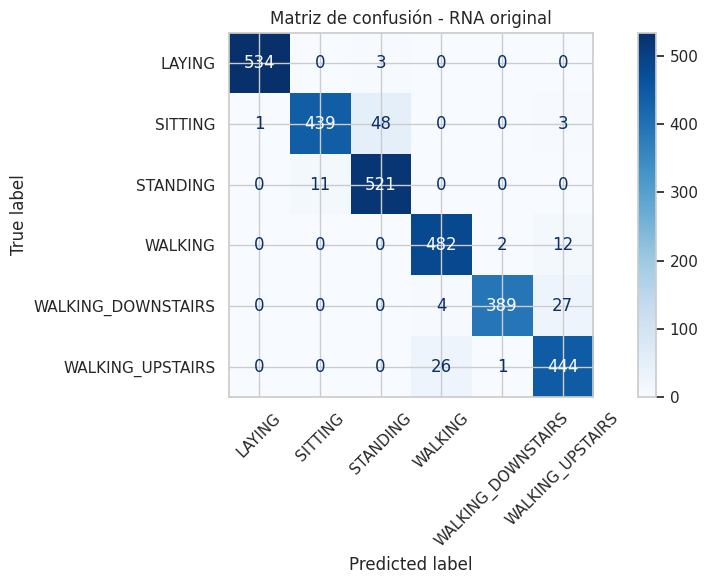

In [78]:
# Preparar los datos
X_train_rna = np.asarray(X_train, dtype=np.float32)
X_test_rna = np.asarray(X_test, dtype=np.float32)

y_train_rna = np.asarray(y_train).ravel()
y_test_rna = np.asarray(y_test).ravel()

# Crear y entrenar la red neuronal
rna_original = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=RANDOM_STATE,
    early_stopping=False
)

rna_original.fit(X_train_rna, y_train_rna)

# Realizar predicciones
y_pred_original = rna_original.predict(X_test_rna)

# Evaluar el modelo
accuracy_original = accuracy_score(y_test_rna, y_pred_original)

print("RESULTADOS RNA - CARACTERÍSTICAS ORIGINALES")
print("-------------------------------------------")
print(f"Exactitud (Accuracy): {accuracy_original:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test_rna, y_pred_original))

# Matriz de confusión
matriz = confusion_matrix(y_test_rna, y_pred_original)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=rna_original.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - RNA original")
plt.tight_layout()
plt.show()

## 6. Selección de características mediante SFFS

Se aplicará el método Sequential Floating Forward Selection (SFFS), una técnica de selección de características que busca encontrar un subconjunto de variables que proporcione un buen desempeño de clasificación.

El método comienza con un conjunto vacío y agrega progresivamente las características que mejoran el rendimiento del modelo. Además, permite retirar características previamente seleccionadas cuando esto mejora el resultado.

La selección se realizará únicamente con los datos de entrenamiento, evitando utilizar información del conjunto de prueba durante este proceso.

In [79]:
# Preparar matrices conservando los nombres de las características

X_train_sffs = pd.DataFrame(
    X_train_rna,
    columns=X_train.columns
)

X_test_sffs = pd.DataFrame(
    X_test_rna,
    columns=X_test.columns
)

print("Preparación para SFFS")
print("---------------------")
print("Características disponibles:", X_train_sffs.shape[1])
print("Observaciones de entrenamiento:", X_train_sffs.shape[0])
print("Observaciones de prueba:", X_test_sffs.shape[0])
print("Etiquetas de entrenamiento:", len(y_train_rna))

Preparación para SFFS
---------------------
Características disponibles: 561
Observaciones de entrenamiento: 7352
Observaciones de prueba: 2947
Etiquetas de entrenamiento: 7352


In [80]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

# 1. Preselección de las 30 características más informativas
selector_inicial = SelectKBest(
    score_func=lambda X, y: mutual_info_classif(
        X, y, random_state=RANDOM_STATE
    ),
    k=30
)

X_train_reducido = selector_inicial.fit_transform(
    X_train_sffs, y_train_rna
)

# Recuperar los nombres de las características seleccionadas
caracteristicas_candidatas = X_train_sffs.columns[
    selector_inicial.get_support()
]

X_train_candidatas = pd.DataFrame(
    X_train_reducido,
    columns=caracteristicas_candidatas
)

print("Características iniciales:", X_train_sffs.shape[1])
print("Características preseleccionadas:", X_train_candidatas.shape[1])

# 2. Configurar la RNA que evaluará los subconjuntos
rna_sffs = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    max_iter=100,
    random_state=RANDOM_STATE,
    early_stopping=False
)

# 3. Validación cruzada estratificada
validacion_sffs = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 4. Aplicar SFFS
sffs = SFS(
    estimator=rna_sffs,
    k_features=8,
    forward=True,
    floating=True,
    scoring="accuracy",
    cv=validacion_sffs,
    n_jobs=1
)

sffs.fit(X_train_candidatas, y_train_rna)

# 5. Obtener las características seleccionadas
caracteristicas_sffs = list(sffs.k_feature_names_)

print("\nRESULTADOS DE SFFS")
print("------------------")
print("Número de características seleccionadas:", len(caracteristicas_sffs))
print("Exactitud media en validación cruzada:", round(sffs.k_score_, 4))

print("\nCaracterísticas seleccionadas:")
for caracteristica in caracteristicas_sffs:
    print("-", caracteristica)

Características iniciales: 561
Características preseleccionadas: 30


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro


RESULTADOS DE SFFS
------------------
Número de características seleccionadas: 8
Exactitud media en validación cruzada: 0.874

Características seleccionadas:
- tBodyAcc-max()-X
- tBodyAccJerk-max()-Y
- tBodyAccJerk-max()-Z
- tBodyAccJerk-min()-X
- tBodyAccJerk-min()-Z
- tBodyAccMag-max()
- fBodyAcc-bandsEnergy()-1,8
- angle(Y,gravityMean)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


RESULTADOS RNA + SFFS
---------------------
Características utilizadas: 8
Accuracy: 0.8025

Reporte de clasificación:
                    precision    recall  f1-score   support

            LAYING       0.86      0.85      0.85       537
           SITTING       0.74      0.70      0.72       491
          STANDING       0.79      0.80      0.80       532
           WALKING       0.79      0.86      0.82       496
WALKING_DOWNSTAIRS       0.95      0.77      0.85       420
  WALKING_UPSTAIRS       0.73      0.82      0.77       471

          accuracy                           0.80      2947
         macro avg       0.81      0.80      0.80      2947
      weighted avg       0.81      0.80      0.80      2947



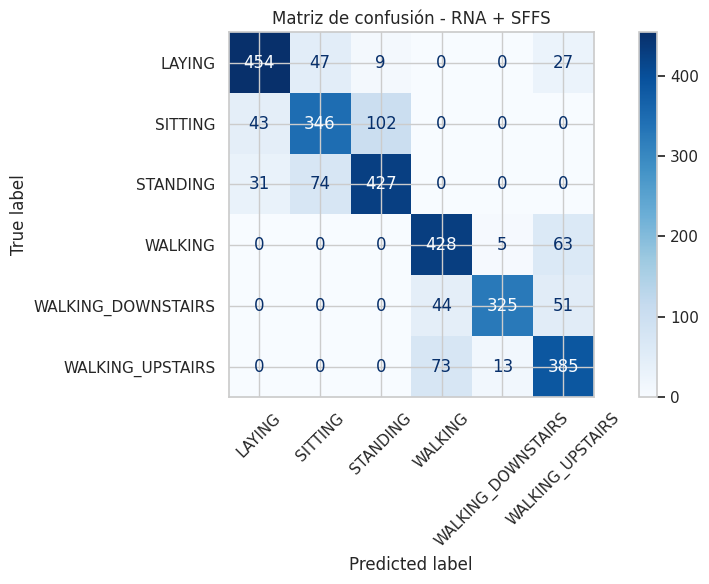

In [81]:
# Seleccionar las mismas 8 características en entrenamiento y prueba
X_train_sffs_final = X_train_sffs[caracteristicas_sffs]
X_test_sffs_final = X_test_sffs[caracteristicas_sffs]

# Crear y entrenar la RNA
rna_sffs_final = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=RANDOM_STATE,
    early_stopping=False
)

rna_sffs_final.fit(X_train_sffs_final, y_train_rna)

# Predicciones
y_pred_sffs = rna_sffs_final.predict(X_test_sffs_final)

# Evaluación
accuracy_sffs = accuracy_score(y_test_rna, y_pred_sffs)

print("RESULTADOS RNA + SFFS")
print("---------------------")
print("Características utilizadas:", len(caracteristicas_sffs))
print(f"Accuracy: {accuracy_sffs:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test_rna, y_pred_sffs))

# Matriz de confusión
matriz_sffs = confusion_matrix(y_test_rna, y_pred_sffs)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_sffs,
    display_labels=rna_sffs_final.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - RNA + SFFS")
plt.tight_layout()
plt.show()

## 7. Reducción de dimensionalidad mediante PCA

Se aplicará el Análisis de Componentes Principales (PCA) para reducir la dimensionalidad del conjunto de datos.

Esta técnica transforma las características originales en componentes principales no correlacionados, ordenados según la cantidad de varianza que explican.

Se conservarán los componentes necesarios para representar al menos el 95 % de la varianza de los datos. Posteriormente, se entrenará una red neuronal artificial utilizando los componentes obtenidos.

RESULTADOS DE PCA
-----------------
Características originales: 561
Componentes seleccionados: 67
Varianza explicada: 0.9505

RESULTADOS RNA + PCA
--------------------
Accuracy: 0.9399

Reporte de clasificación:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.97      0.88      0.92       491
          STANDING       0.90      0.97      0.94       532
           WALKING       0.91      0.97      0.94       496
WALKING_DOWNSTAIRS       0.94      0.92      0.93       420
  WALKING_UPSTAIRS       0.92      0.88      0.90       471

          accuracy                           0.94      2947
         macro avg       0.94      0.94      0.94      2947
      weighted avg       0.94      0.94      0.94      2947



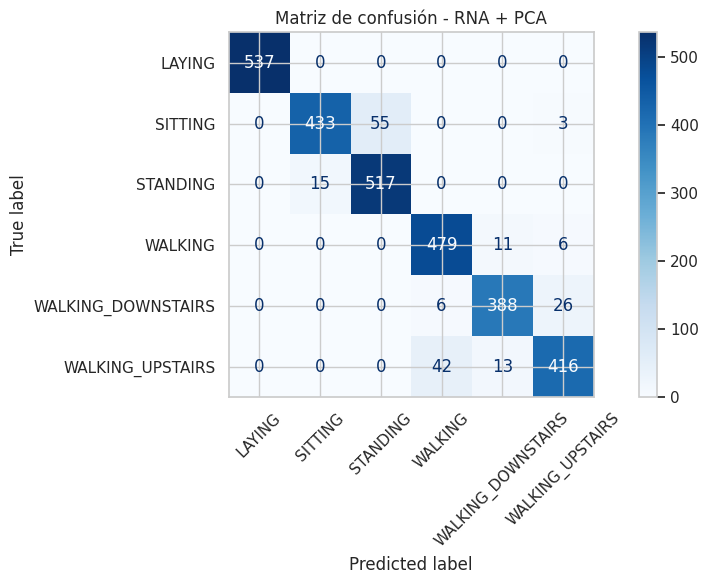

In [82]:
from sklearn.decomposition import PCA

# 1. Ajustar PCA únicamente con los datos de entrenamiento
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_rna)

# Transformar los datos de prueba
X_test_pca = pca.transform(X_test_rna)

print("RESULTADOS DE PCA")
print("-----------------")
print("Características originales:", X_train_rna.shape[1])
print("Componentes seleccionados:", pca.n_components_)
print(f"Varianza explicada: {sum(pca.explained_variance_ratio_):.4f}")

# 2. Entrenar RNA con los componentes principales
rna_pca = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=RANDOM_STATE,
    early_stopping=False
)

rna_pca.fit(X_train_pca, y_train_rna)

# 3. Predicciones
y_pred_pca = rna_pca.predict(X_test_pca)

# 4. Evaluación
accuracy_pca = accuracy_score(y_test_rna, y_pred_pca)

print("\nRESULTADOS RNA + PCA")
print("--------------------")
print(f"Accuracy: {accuracy_pca:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test_rna, y_pred_pca))

# 5. Matriz de confusión
matriz_pca = confusion_matrix(y_test_rna, y_pred_pca)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_pca,
    display_labels=rna_pca.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - RNA + PCA")
plt.tight_layout()
plt.show()

## 8. Reducción de dimensionalidad mediante LDA

Se aplicará el Análisis Discriminante Lineal (LDA), una técnica supervisada que busca encontrar nuevas dimensiones que maximicen la separación entre las diferentes clases.

Debido a que el conjunto de datos contiene seis actividades, LDA puede generar como máximo cinco componentes discriminantes.

Posteriormente, se entrenará una red neuronal artificial utilizando los componentes obtenidos y se evaluará su desempeño sobre el conjunto de prueba.

RESULTADOS DE LDA
-----------------
Características originales: 561
Componentes discriminantes: 5

RESULTADOS RNA + LDA
--------------------
Accuracy: 0.9620

Reporte de clasificación:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       537
           SITTING       0.96      0.86      0.91       491
          STANDING       0.88      0.97      0.92       532
           WALKING       0.98      0.99      0.98       496
WALKING_DOWNSTAIRS       1.00      0.98      0.99       420
  WALKING_UPSTAIRS       0.97      0.98      0.97       471

          accuracy                           0.96      2947
         macro avg       0.96      0.96      0.96      2947
      weighted avg       0.96      0.96      0.96      2947



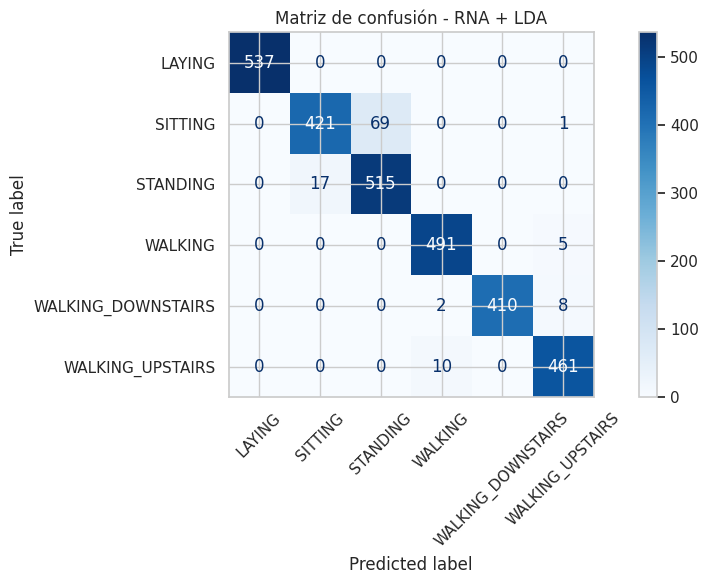

In [83]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 1. Aplicar LDA
lda = LinearDiscriminantAnalysis(n_components=5)

X_train_lda = lda.fit_transform(X_train_rna, y_train_rna)
X_test_lda = lda.transform(X_test_rna)

print("RESULTADOS DE LDA")
print("-----------------")
print("Características originales:", X_train_rna.shape[1])
print("Componentes discriminantes:", X_train_lda.shape[1])

# 2. Entrenar RNA
rna_lda = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=RANDOM_STATE,
    early_stopping=False
)

rna_lda.fit(X_train_lda, y_train_rna)

# 3. Predicciones
y_pred_lda = rna_lda.predict(X_test_lda)

# 4. Evaluación
accuracy_lda = accuracy_score(y_test_rna, y_pred_lda)

print("\nRESULTADOS RNA + LDA")
print("--------------------")
print(f"Accuracy: {accuracy_lda:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test_rna, y_pred_lda))

# 5. Matriz de confusión
matriz_lda = confusion_matrix(y_test_rna, y_pred_lda)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_lda,
    display_labels=rna_lda.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión - RNA + LDA")
plt.tight_layout()
plt.show()

## 9. Comparación de los modelos de clasificación

Se comparan los cuatro modelos implementados: RNA original, RNA con selección SFFS, RNA con PCA y RNA con LDA.

La evaluación considera Accuracy, F1-score macro y F1-score ponderado. También se tiene en cuenta la cantidad de características o componentes utilizados por cada modelo.

,Modelo,Dimensiones,Accuracy,Precision macro,Recall macro,F1 macro,F1 ponderado
0,RNA original,561,0.9532,0.9553,0.9514,0.9526,0.9532
1,RNA + SFFS,8,0.8025,0.8099,0.8011,0.8033,0.8030
2,RNA + PCA,67,0.9399,0.9406,0.9377,0.9384,0.9397
3,RNA + LDA,5,0.9620,0.9650,0.9617,0.9625,0.9618


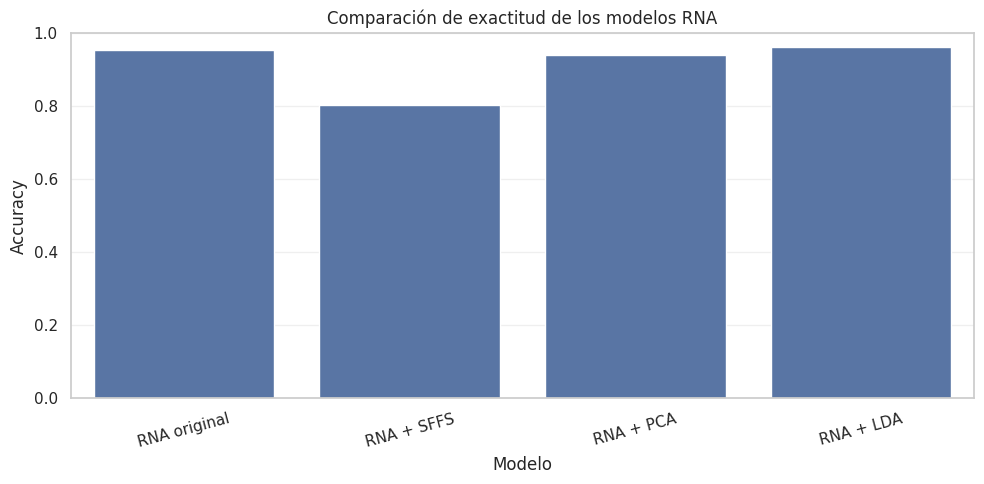

In [85]:
from sklearn.metrics import f1_score, precision_score, recall_score

# Organizar predicciones de los cuatro modelos
modelos = {
    "RNA original": (y_pred_original, 561),
    "RNA + SFFS": (y_pred_sffs, len(caracteristicas_sffs)),
    "RNA + PCA": (y_pred_pca, pca.n_components_),
    "RNA + LDA": (y_pred_lda, X_train_lda.shape[1])
}

resultados_modelos = []

for nombre, (predicciones, dimensiones) in modelos.items():

    resultados_modelos.append({
        "Modelo": nombre,
        "Dimensiones": dimensiones,
        "Accuracy": accuracy_score(y_test_rna, predicciones),
        "Precision macro": precision_score(
            y_test_rna, predicciones, average="macro"
        ),
        "Recall macro": recall_score(
            y_test_rna, predicciones, average="macro"
        ),
        "F1 macro": f1_score(
            y_test_rna, predicciones, average="macro"
        ),
        "F1 ponderado": f1_score(
            y_test_rna, predicciones, average="weighted"
        )
    })

tabla_resultados = pd.DataFrame(resultados_modelos)

display(tabla_resultados.round(4))

# Gráfica comparativa de exactitud
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_resultados,
    x="Modelo",
    y="Accuracy"
)

plt.title("Comparación de exactitud de los modelos RNA")
plt.xlabel("Modelo")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Conclusiones de la clasificación

Se implementaron cuatro modelos de clasificación basados en redes neuronales artificiales, utilizando diferentes estrategias de reducción de dimensionalidad.

El modelo RNA original obtuvo una exactitud del 95,32 % utilizando las 561 características disponibles.

La estrategia SFFS permitió reducir las características a solamente 8, obteniendo una exactitud del 80,25 %. Esto evidencia que una reducción muy agresiva puede ocasionar pérdida de información relevante para la clasificación.

PCA permitió conservar 67 componentes principales que representan el 95 % de la varianza, alcanzando una exactitud del 93,99 %, un resultado cercano al modelo original.

Por otra parte, LDA obtuvo el mejor desempeño, con una exactitud del 96,20 % utilizando únicamente 5 componentes discriminantes. Esto demuestra la utilidad de una técnica supervisada que busca maximizar la separación entre las diferentes actividades.

En conclusión, LDA presentó el mejor equilibrio entre reducción de dimensionalidad y capacidad de clasificación. Por tanto, fue la estrategia más efectiva entre las evaluadas para el reconocimiento de actividades humanas en este conjunto de datos.